In [49]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import CIFAR100
from torchvision import transforms, models
# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ==========================================
# TIỀN XỬ LÝ DỮ LIỆU & AUGMENTATION
# ==========================================
# Chuẩn hóa theo Mean và Std của bộ dữ liệu CIFAR-100
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4867, 0.4408), (0.2675, 0.2565, 0.2761))
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4867, 0.4408), (0.2675, 0.2565, 0.2761))
])
# 4. Khởi tạo Dataset chuẩn
raw_train_dataset  = CIFAR100(root="data", train=True, download=True, transform=transform_train)
raw_val_dataset    = CIFAR100(root="data", train=True, download=False, transform=transform_test)
final_test_dataset = CIFAR100(root="data", train=False, download=True, transform=transform_test)

# 5. Chia Train (90%) - Val (10%) từ 50,000 mẫu
total_samples = len(raw_train_dataset)
train_size = int(0.9 * total_samples)
val_size = total_samples - train_size

generator = torch.Generator().manual_seed(42)
permuted_indices = torch.randperm(total_samples, generator=generator).tolist()

train_indices = permuted_indices[:train_size]
val_indices   = permuted_indices[train_size:]

TRAIN_SUBSET = Subset(raw_train_dataset, train_indices)
VAL_SUBSET   = Subset(raw_val_dataset, val_indices)

# 6. DataLoader với num_workers=0 để tránh lỗi Shared Memory (shm)
BATCH_SIZE = 64
train_loader = DataLoader(TRAIN_SUBSET, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader   = DataLoader(VAL_SUBSET, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(final_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

In [50]:
class PathEmbedding(nn.Module):
    """
    Chuyển đổi ảnh (B, C, H, W) thành các patch embedding (B, num_patches(N), embed_dim(D))
    Sử dụng Conv2d với kernel_size=path_size và stride=path_size để tạo các patch embedding.
    """
    def __init__(self, in_channels=3, patch_size=4, embed_size=256, image_size=32):
        super(PathEmbedding, self).__init__()
        self.patch_size = patch_size
        self.num_patches = (image_size // patch_size) ** 2
        # Sử dụng Conv2d làm nhiệm vụ chia patch + chiếu tuyến tính cùng lúc
        self.proj = nn.Conv2d(in_channels, embed_size, kernel_size=patch_size, stride=patch_size)

        #Class TOken đại diện cho toàn bộ ảnh,
        self.cls_token = nn.Parameter(torch.randn(1, 1, embed_size))

        #Position Embedding học vị trí không gian của từng patch.
        self.pos_embedding = nn.Parameter(torch.randn(1, self.num_patches + 1, embed_size))

    def forward(self, x):
        B = x.shape[0]
        #x: (B, C, H, W) -> (B, D, H/P, W/P)
        # Chia patch và chiếu tuyến tính
        x = self.proj(x)  # (B, D, H', W')
        #Flatten các patch embedding thành (B, D, N) với N = số lượng patch
        x = x.flatten(2)  # (B, D, N)
        x = x.transpose(1, 2)  # (B, N, D)

        # Thêm class token vào đầu chuỗi patch embedding
        cls_tokens = self.cls_token.expand(B, -1, -1)  # (B, 1, D)
        #Nối class token vào đầu chuỗi patch embedding
        x = torch.cat((cls_tokens, x), dim=1)  # (B, N+1, D)

        # Thêm position embedding
        x = x + self.pos_embedding[:, :x.size(1), :]

        return x

In [51]:
class MultiHeadSelfAttention(nn.Module):
    """
    Tầng Scaled Dot-Product Multi-Head Self-Attention
    """
    def __init__(self, emb_size=256, num_heads=8, dropout=0.1):
        super().__init__()
        self.emb_size = emb_size
        self.num_heads = num_heads
        self.head_dim = emb_size // num_heads
        self.scale = self.head_dim ** -0.5

        self.qkv = nn.Linear(emb_size, emb_size * 3)
        self.fc_out = nn.Linear(emb_size, emb_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, N, D = x.shape
        # Tạo Q, K, V cùng lúc: (B, N, 3 * D) -> 3 x (B, num_heads, N, head_dim)
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]

        # Dot product Q và K: (B, heads, N, head_dim) x (B, heads, head_dim, N) -> (B, heads, N, N)
        attn_scores = (q @ k.transpose(-2, -1)) * self.scale
        attn_weights = torch.softmax(attn_scores, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Trọng số x V: (B, heads, N, N) x (B, heads, N, head_dim) -> (B, heads, N, head_dim)
        out = attn_weights @ v
        out = out.transpose(1, 2).reshape(B, N, D)
        return self.fc_out(out)

In [52]:
class TransformerEncoderBlock(nn.Module):
    """
    Một khối Transformer Encoder (LayerNorm -> MSA -> Residual -> LayerNorm -> MLP -> Residual)
    """
    def __init__(self, emb_size=256, num_heads=8, forward_expansion=4, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(emb_size)
        self.attn = MultiHeadSelfAttention(emb_size, num_heads, dropout)
        
        self.norm2 = nn.LayerNorm(emb_size)
        self.mlp = nn.Sequential(
            nn.Linear(emb_size, forward_expansion * emb_size),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(forward_expansion * emb_size, emb_size),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        # Pre-LN Residual Connections
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x

In [53]:
class VisionTransformer(nn.Module):
    """
    Mô hình ViT hoàn chỉnh cho CIFAR-100
    """
    def __init__(
        self, 
        img_size=32, 
        patch_size=4, 
        in_channels=3, 
        num_classes=100, 
        emb_size=256, 
        depth=6, 
        num_heads=8, 
        dropout=0.1
    ):
        super().__init__()
        self.patch_embed = PatchEmbedding(in_channels, patch_size, emb_size, img_size)
        
        self.encoder = nn.ModuleList([
            TransformerEncoderBlock(emb_size, num_heads, dropout=dropout)
            for _ in range(depth)
        ])
        
        self.norm = nn.LayerNorm(emb_size)
        self.classifier = nn.Linear(emb_size, num_classes)

    def forward(self, x):
        x = self.patch_embed(x)
        
        for layer in self.encoder:
            x = layer(x)
            
        x = self.norm(x)
        # Chỉ lấy đầu ra của Class Token (vị trí đầu tiên) để phân loại
        cls_head = x[:, 0]
        return self.classifier(cls_head)

In [54]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)
        
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

In [55]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    
    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * images.size(0)
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
            
    return running_loss / total, correct / total

In [56]:
def save_and_update_history_json(new_history, filepath="vit_cifar100_history.json"):
    """Ghi hoặc cập nhật lịch sử huấn luyện vào file JSON."""
    history = {}
    if os.path.exists(filepath):
        with open(filepath, "r", encoding="utf-8") as f:
            try:
                history = json.load(f)
            except json.JSONDecodeError:
                history = {}

    # Nối tiếp danh sách lịch sử nếu đã có từ trước
    for key, values in new_history.items():
        if key in history:
            history[key].extend(values)
        else:
            history[key] = values

    with open(filepath, "w", encoding="utf-8") as f:
        json.dump(history, f, indent=4, ensure_ascii=False)

    return history

In [57]:
# ==========================================
# KHỞI TẠO MÔ HÌNH & VÒNG LẶP HUẤN LUYỆN
# ==========================================
model = VisionTransformer(
    img_size=32,
    patch_size=4,
    in_channels=3,
    num_classes=100,
    emb_size=256,
    depth=6,
    num_heads=8,
    dropout=0.1
).to(device)

In [58]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)

TRAINING LOOP

In [59]:
best_val_acc = 0.0
checkpoint_path = "best_vit_cifar100.pth"
json_path = "vit_cifar100_history.json"

current_run_history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}
BATCH_SIZE = 64
NUM_EPOCHS = 50
print("\n--- BẮT ĐẦU HUẤN LUYỆN ---")
for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc     = evaluate(model, val_loader, criterion, device)
    
    # Cập nhật Learning Rate Scheduler
    scheduler.step()
    
    # Cập nhật thông số từng epoch vào dict
    current_run_history['train_loss'].append(round(train_loss, 4))
    current_run_history['train_acc'].append(round(train_acc * 100, 2))
    current_run_history['val_loss'].append(round(val_loss, 4))
    current_run_history['val_acc'].append(round(val_acc * 100, 2))   
    
    # In định dạng chuỗi f-string
    print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS:02d}] | "
          f"Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.2f}%")
    
    # Lưu checkpoint mô hình tốt nhất dựa trên Validation Accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), checkpoint_path)
        print(f"  --> Đã lưu model mới tốt nhất với Val Acc: {val_acc*100:.2f}%")

# LƯU & CẬP NHẬT VÀO FILE JSON
full_history = save_and_update_history_json(current_run_history, filepath=json_path)

# ==========================================
# 6. ĐÁNH GIÁ TRÊN TẬP TEST
# ==========================================
print("\n--- ĐÁNH GIÁ TRÊN TẬP TEST ---")
# Load lại trọng số tốt nhất đã lưu
model.load_state_dict(torch.load(checkpoint_path, weights_only=True))
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc*100:.2f}%")


--- BẮT ĐẦU HUẤN LUYỆN ---
Epoch [01/50] | Train Loss: 3.9112 - Train Acc: 9.56% | Val Loss: 3.4955 - Val Acc: 15.82%
  --> Đã lưu model mới tốt nhất với Val Acc: 15.82%
Epoch [02/50] | Train Loss: 3.3984 - Train Acc: 17.65% | Val Loss: 3.1810 - Val Acc: 22.60%
  --> Đã lưu model mới tốt nhất với Val Acc: 22.60%
Epoch [03/50] | Train Loss: 3.1585 - Train Acc: 22.05% | Val Loss: 2.9749 - Val Acc: 26.04%
  --> Đã lưu model mới tốt nhất với Val Acc: 26.04%
Epoch [04/50] | Train Loss: 2.9801 - Train Acc: 25.57% | Val Loss: 2.8531 - Val Acc: 29.20%
  --> Đã lưu model mới tốt nhất với Val Acc: 29.20%
Epoch [05/50] | Train Loss: 2.7954 - Train Acc: 29.28% | Val Loss: 2.7327 - Val Acc: 31.22%
  --> Đã lưu model mới tốt nhất với Val Acc: 31.22%
Epoch [06/50] | Train Loss: 2.6214 - Train Acc: 32.73% | Val Loss: 2.6212 - Val Acc: 33.60%
  --> Đã lưu model mới tốt nhất với Val Acc: 33.60%
Epoch [07/50] | Train Loss: 2.4606 - Train Acc: 36.37% | Val Loss: 2.5193 - Val Acc: 36.26%
  --> Đã lưu mode

Đã lưu biểu đồ vào file 'vit_cifar100_learning_curves.png'


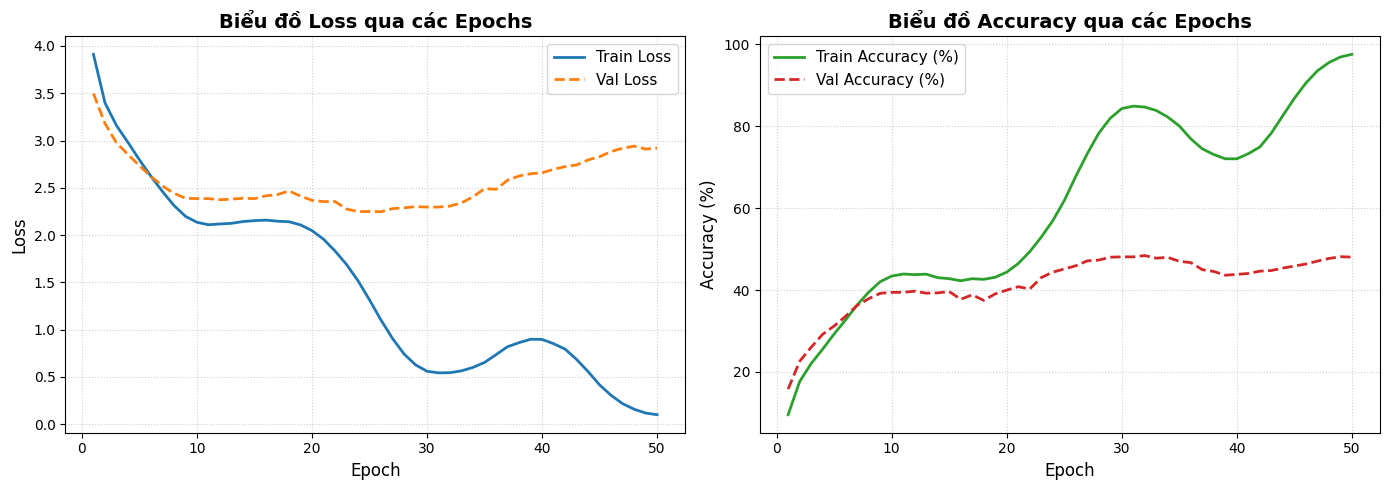

In [60]:
import matplotlib.pyplot as plt

def plot_training_history(json_path="vit_cifar100_history.json"):
    # 1. Kiểm tra sự tồn tại của file JSON
    if not os.path.exists(json_path):
        print(f"Lỗi: Không tìm thấy file '{json_path}'. Hãy đảm bảo file đã được tạo sau khi train.")
        return

    # 2. Đọc dữ liệu từ file JSON
    with open(json_path, "r", encoding="utf-8") as f:
        history = json.load(f)

    train_loss = history.get("train_loss", [])
    val_loss = history.get("val_loss", [])
    train_acc = history.get("train_acc", [])
    val_acc = history.get("val_acc", [])

    epochs = range(1, len(train_loss) + 1)

    # 3. Tạo đồ thị
    plt.figure(figsize=(14, 5))

    # --- Đồ thị 1: Train Loss vs Val Loss ---
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_loss, label="Train Loss", color="#1f77b4", linewidth=2)
    plt.plot(epochs, val_loss, label="Val Loss", color="#ff7f0e", linewidth=2, linestyle="--")
    plt.title("Biểu đồ Loss qua các Epochs", fontsize=14, fontweight="bold")
    plt.xlabel("Epoch", fontsize=12)
    plt.ylabel("Loss", fontsize=12)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(fontsize=11)

    # --- Đồ thị 2: Train Accuracy vs Val Accuracy ---
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_acc, label="Train Accuracy (%)", color="#2ca02c", linewidth=2)
    plt.plot(epochs, val_acc, label="Val Accuracy (%)", color="#d62728", linewidth=2, linestyle="--")
    plt.title("Biểu đồ Accuracy qua các Epochs", fontsize=14, fontweight="bold")
    plt.xlabel("Epoch", fontsize=12)
    plt.ylabel("Accuracy (%)", fontsize=12)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(fontsize=11)

    # Tối ưu khoảng cách giữa các đồ thị và lưu/hiển thị
    plt.tight_layout()
    plt.savefig("vit_cifar100_learning_curves.png", dpi=300)
    print("Đã lưu biểu đồ vào file 'vit_cifar100_learning_curves.png'")
    plt.show()

plot_training_history("vit_cifar100_history.json")